In [1]:
import numpy as np
import pandas as pd
import gc
from sklearn.preprocessing import MinMaxScaler
from sklearn.utils import resample
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.decomposition import PCA
import datetime
from datetime import timedelta
import random
from imblearn.over_sampling import RandomOverSampler
from numba import njit
import numba as nb
from scipy.stats import zscore
import json
from scipy.stats import spearmanr
import websocket
import warnings
warnings.filterwarnings('ignore')
import random as python_random
import statsmodels.api as sm
import joblib
import sys
import time
import traceback
import torch
import torch.nn as nn
import torch.nn.functional as F 
import os
import importlib
TL = importlib.import_module("torch")
NN = TL.nn
F = importlib.import_module("torch.nn.functional")

from scipy.stats import spearmanr
np.random.seed(150)
python_random.seed(150)
import itertools
import copy

In [2]:
#Download ETH data from ex
#Loading data
data =  pd.read_csv(r'eth_2026_up.csv')


#Calculating AVG
data['Avg'] = (data['Open']+data['Low']+data['High']+data['Close'])/4
data = data[['Open', 'High','Low','Close','Volume','datetime','Avg']]

data = data.dropna()
data['Log'] = np.log(data['Avg'])

hold_pos = 20


data

,Open,High,Low,Close,Volume,datetime,Avg,Log
0,2450.38,2451.21,2446.07,2446.13,2820.517,2026-02-01 00:00:00,2448.4475,7.803209
1,2446.12,2446.84,2444.26,2446.24,2621.399,2026-02-01 00:01:00,2445.8650,7.802154
2,2446.24,2455.69,2445.83,2455.42,2888.893,2026-02-01 00:02:00,2450.7950,7.804168
3,2455.41,2458.37,2452.76,2454.23,6589.965,2026-02-01 00:03:00,2455.1925,7.805960
4,2454.23,2455.16,2451.60,2452.49,2427.853,2026-02-01 00:04:00,2453.3700,7.805218
...,...,...,...,...,...,...,...,...
305275,2465.76,2465.77,2465.04,2465.40,525.214,2026-08-31 23:55:00,2465.4925,7.810147
305276,2465.40,2465.40,2464.71,2465.33,529.030,2026-08-31 23:56:00,2465.2100,7.810032
305277,2465.34,2466.50,2465.34,2466.01,329.737,2026-08-31 23:57:00,2465.7975,7.810271
305278,2466.01,2466.01,2466.00,2466.01,150.804,2026-08-31 23:58:00,2466.0075,7.810356


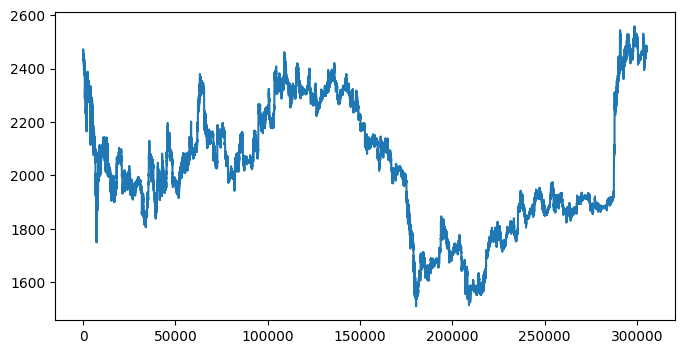

In [3]:
plt.figure(figsize=(8,4))
plt.plot(data['Avg'])

In [4]:
#@njit
def run_rolling_nis_dynamic_numba(log_prices, periods, q_lookback, Q_scale=0.1, R_scale=1.0):
    n = len(log_prices)
    sum_nis_output = np.empty(n, dtype=np.float64)
    sum_nis_output[:] = np.nan
    n2 = periods - 1

    # O loop começa garantindo que temos histórico suficiente para o q_lookback e para a janela de teste
    start_idx = max(n2, q_lookback)
    

    # Loop Externo: Desliza a janela de teste ao longo do tempo
    for i in range(start_idx, n):
        window_start = i - n2
        
        # 1. CÁLCULO DINÂMICO: Extrai o histórico estritamente anterior à janela atual
        # Ex: Se q_lookback=120, olha os 120 retornos passados para calibrar o momento atual
        hist_start = window_start - q_lookback
        if hist_start < 0:
            hist_start = 0
            
        hist_prices = log_prices[hist_start : window_start + 1]
        
        # Calcula retornos e variância dinamicamente para esta barra específica
        if len(hist_prices) > 1:
            hist_returns = hist_prices[1:] - hist_prices[:-1]
            base_variance = np.var(hist_returns)
        else:
            base_variance = 1e-8

        # Se o mercado congelar/平, evita divisão por zero
        if base_variance <= 0.0: 
            base_variance = 1e-8

        # 2. ATUALIZAÇÃO DINÂMICA DE Q E R
        global_q = base_variance * Q_scale
        global_r = base_variance * R_scale

        # Inicialização do Filtro para a janela atual com os parâmetros novos
        state_estimate = log_prices[window_start]
        P = global_r 
        window_sum_nis = 0.0

        # Loop Interno: Roda o Filtro de Kalman local com o Q e R atualizados
        for j in range(1, periods):
            price_t = log_prices[window_start + j]

            # Predição
            pred_state = state_estimate
            pred_P = P + global_q

            # Atualização
            innovation = price_t - pred_state
            S_t = pred_P + global_r

            # Acúmulo do NIS
            nis_t = (innovation ** 2) / S_t
            window_sum_nis += nis_t

            # Atualização dos Estados
            K_t = pred_P / S_t
            state_estimate = pred_state + K_t * innovation
            P = (1.0 - K_t) * pred_P

        sum_nis_output[i] = window_sum_nis

    return sum_nis_output

In [5]:
def scan_dataframe_fast_dynamic(df, periods=90, q_lookback=180):
    log_prices_arr = df['Log'].to_numpy()
    

    # Executa a função dinâmica (Q e R mudam a cada linha do dataframe)
    sum_nis_array = run_rolling_nis_dynamic_numba(
        log_prices_arr, periods, q_lookback, Q_scale=0.01, R_scale=10.0
    )

    # Wilson-Hilferty para Chi-Squared 95%
    df_degrees = periods - 1
    z_90 = 1.2815515655446004
    z_95 = 1.6448536269514722
    z_99 = 2.326
    critical_value = df_degrees * (1.0 - 2.0 / (9.0 * df_degrees) + z_95 * np.sqrt(2.0 / (9.0 * df_degrees))) ** 3

    df['sum_nis'] = sum_nis_array
    df['is_stationary'] = sum_nis_array <= critical_value
    df['market_regime'] = np.where(
        df['sum_nis'].isna(), 'WARMUP',
        np.where(df['is_stationary'], 'STATIONARY', 'NON-STATIONARY')
    )
    
    return df

In [6]:
data = scan_dataframe_fast_dynamic(data, periods=10, q_lookback=60)
stationary = len(data[data['market_regime']=='STATIONARY'])
non_stationary = len(data[data['market_regime']=='NON-STATIONARY'])       
print(stationary/(stationary+non_stationary))

0.9701199135050128


In [7]:
# Function to create factors and define targets
def dat(data, hold_pos):

    df = pd.DataFrame(data)

    
    ###############AROON ##################
    
    @njit
    def fast_aroon_osc(high, low, window):
        n = len(high)
        out = np.full(n, np.nan)

        for i in range(window - 1, n):
            # Busca o máximo e mínimo na janela manualmente (muito rápido no Numba)
            max_idx = 0
            min_idx = 0
            max_val = high[i - window + 1]
            min_val = low[i - window + 1]

            for j in range(1, window):
                curr_h = high[i - window + 1 + j]
                curr_l = low[i - window + 1 + j]

                if curr_h >= max_val:
                    max_val = curr_h
                    max_idx = j
                if curr_l <= min_val:
                    min_val = curr_l
                    min_idx = j

            up = ((max_idx + 1) / window) * 100
            down = ((min_idx + 1) / window) * 100
            out[i] = up - down
            
        return out

    # No seu loop:
    high_arr = df['High'].values
    low_arr = df['Low'].values

    for i in range(15, 256, 10):
        df[f'AAR_{i}'] = fast_aroon_osc(high_arr, low_arr, i)
        
        
        
    ######################### Volume profile####################################
        
    @njit
    def fast_poc_expanding_numba(close, volume, max_window=300, min_periods=70, bins=20):
        n = len(close)
        out = np.full(n, np.nan)

        # Começamos a calcular apenas após atingir o min_periods (70)
        for i in range(min_periods - 1, n):
            # Lógica da Janela Expansiva:
            # Se i < 300, a janela é [0 : i+1] (tamanho i+1)
            # Se i >= 300, a janela é [i-299 : i+1] (tamanho fixo 300)
            start = max(0, i - max_window + 1)

            w_close = close[start : i + 1]
            w_vol = volume[start : i + 1]

            p_min = np.min(w_close)
            p_max = np.max(w_close)

            if p_min >= p_max:
                out[i] = 0.0
                continue

            # Histograma manual (Otimizado para Numba)
            hist = np.zeros(bins)
            bin_width = (p_max - p_min) / bins

            for j in range(len(w_close)):
                # Calcula o bin correspondente
                val = w_close[j]
                idx = int((val - p_min) / bin_width)
                if idx >= bins: 
                    idx = bins - 1 # Garante que o valor máximo entre no último bin
                hist[idx] += w_vol[j]

            # Encontra o bin com maior volume (Point of Control)
            max_bin_idx = np.argmax(hist)
            poc = p_min + (max_bin_idx + 0.5) * bin_width

            # p_last / poc - 1 (Sinal de desvio do preço médio de volume)
            out[i] = close[i] / poc - 1

        return out

    # Chamada corrigida
    df['Vpro_20'] = fast_poc_expanding_numba(
        df['Close'].values, 
        df['Volume'].values, 
        max_window=300, 
        min_periods=70,
        bins=20
    )
    
   
    
       
    
    
    
     ############## VWAP #################
   
    @njit
    
    def fast_vwap_zscore(close, high, low, volume, max_window=300, min_periods=30):
        n = len(close)
        vwap_z = np.full(n, np.nan)

        # Preço Típico ponderado por Volume: (H+L+C)/3 * Vol
        tp_vol = ((close + high + low) / 3.0) * volume

        for i in range(min_periods - 1, n):
            # Define o início da janela (expansiva até max_window)
            start = max(0, i - max_window + 1)

            # Somas para o VWAP
            sum_tp_vol = np.sum(tp_vol[start : i + 1])
            sum_vol = np.sum(volume[start : i + 1])

            if sum_vol == 0:
                vwap_z[i] = 0.0
                continue

            current_vwap = sum_tp_vol / sum_vol

            # Para o Z-Score (df['Close'] - vwap) / std(vwap)
            # Note: Seu código original calcula o desvio padrão do HISTÓRICO do VWAP
            if i >= start + min_periods:
                # Precisamos calcular o desvio padrão dos valores de VWAP na janela
                # Para performance, vamos extrair o histórico de VWAPs parciais
                window_vwaps = np.zeros(i - start + 1)
                temp_tp_vol = 0.0
                temp_vol = 0.0

                # Este sub-loop calcula o histórico de VWAPs para o desvio padrão
                for k in range(start, i + 1):
                    temp_tp_vol = np.sum(tp_vol[start : k + 1])
                    temp_vol = np.sum(volume[start : k + 1])
                    window_vwaps[k - start] = temp_tp_vol / temp_vol if temp_vol != 0 else current_vwap

                std_vwap = np.std(window_vwaps)

                if std_vwap != 0:
                    vwap_z[i] = (close[i] - current_vwap) / std_vwap
                else:
                    vwap_z[i] = 0.0

        return vwap_z
    
   # Chamada no DataFrame
   
    
    df['VWAP_300'] = fast_vwap_zscore(
        df['Close'].values, df['High'].values, 
        df['Low'].values, df['Volume'].values, 300
    )
    
    ###### Weighted MACD short term ######
        
    @nb.njit(parallel=True, cache=True)
    def calculate_vwap_numba(Close, Low, High, Volume, window, min_periods):
        """Calculates a moving 300-period VWAP using pre-allocated native arrays."""
        n = len(Close)
        vwap_base = np.empty(n)
        vwap_base[:] = np.nan

        # Pre-calculate Typical Price * Volume
        t_pr_vol = ((Close + Low + High) / 3.0) * Volume

        # Parallel window processing
        for i in nb.prange(n):
            if i < min_periods - 1:
                continue
            start = max(0, i - window + 1)

            sum_t_pr = 0.0
            sum_vol = 0.0
            for j in range(start, i + 1):
                sum_t_pr += t_pr_vol[j]
                sum_vol += Volume[j]

            if sum_vol != 0.0:
                vwap_base[i] = sum_t_pr / sum_vol

        return Close / vwap_base - 1.0

    @nb.njit(cache=True)
    def ewm_numba(arr, span):
        """Calculates Exponential Moving Average matching Pandas 'adjust=False'."""
        n = len(arr)
        out = np.empty(n, dtype=np.float64) # 🟢 FIXED: Allocates a clean, isolated array in memory
        if n == 0:
            return out

        alpha = 2.0 / (span + 1.0)

        # Safely prime the first valid element
        if n > 0:
            out[0] = arr[0]

        for i in range(1, n):
            if np.isnan(arr[i]):
                out[i] = out[i-1]
            elif np.isnan(out[i-1]):
                out[i] = arr[i]
            else:
                out[i] = arr[i] * alpha + out[i-1] * (1.0 - alpha)
        return out

    @nb.njit(cache=True)
    def rolling_mean_numba(arr, window):
        """Calculates standard Simple Moving Average (SMA)."""
        n = len(arr)
        out = np.empty(n)
        out[:] = np.nan

        if n < window:
            return out

        current_sum = 0.0
        for i in range(window):
            current_sum += arr[i]
        out[window - 1] = current_sum / window

        for i in range(window, n):
            current_sum += arr[i] - arr[i - window]
            out[i] = current_sum / window
        return out

    @nb.njit(parallel=True, cache=True)
    def process_signals_numba(Close, vwap2, n1, n2, n3):
        """Processes MACD EWM/Rolling layers and handles vectorized signal logic."""
        n = len(Close)

        # --- 1. EXPONENTIAL MACD LAYER (EWM) ---
        ma_fast_ewm = ewm_numba(Close, n1)
        ma_slow_ewm = ewm_numba(Close, n2)
        ma_ewm = ma_fast_ewm - ma_slow_ewm
        sig_ewm = ewm_numba(ma_ewm, n3)
        macds_ewm = ma_ewm - sig_ewm
        macd_out = np.zeros(n)

        # --- 2. ROLLING MACD LAYER (SMA) ---
        ma_fast_roll = rolling_mean_numba(Close, n1)
        ma_slow_roll = rolling_mean_numba(Close, n2)
        ma_roll = ma_fast_roll - ma_slow_roll
        sig_roll = ewm_numba(ma_roll, n3)
        macds_roll = ma_roll - sig_roll
        macdn_out = np.zeros(n)

        # --- 3. SIGNAL TRIGGERING AND HISTOGRAM LOGIC ---
        for t in nb.prange(1, n):
            # EWM Signals (Utilizes trend filter via vwap2)
            cross_up_ewm = (ma_ewm[t] > sig_ewm[t]) and (ma_ewm[t-1] <= sig_ewm[t-1])
            cross_down_ewm = (ma_ewm[t] < sig_ewm[t]) and (ma_ewm[t-1] >= sig_ewm[t-1])

            cond_long_ewm = (ma_ewm[t] < 0.0) and cross_up_ewm and (vwap2[t] > 0.0)
            cond_short_ewm = (ma_ewm[t] > 0.0) and cross_down_ewm and (vwap2[t] < 0.0)

            if cond_long_ewm or cond_short_ewm:
                macd_out[t] = macds_ewm[t]

            # Rolling Signals
            if np.isnan(ma_roll[t]) or np.isnan(sig_roll[t]) or np.isnan(ma_roll[t-1]) or np.isnan(sig_roll[t-1]):
                continue

            cross_up_roll = (ma_roll[t] > sig_roll[t]) and (ma_roll[t-1] <= sig_roll[t-1])
            cross_down_roll = (ma_roll[t] < sig_roll[t]) and (ma_roll[t-1] >= sig_roll[t-1])

            cond_long_roll = (ma_roll[t] < 0.0) and cross_up_roll
            cond_short_roll = (ma_roll[t] > 0.0) and cross_down_roll

            if cond_long_roll or cond_short_roll:
                macdn_out[t] = macds_roll[t]

        return macd_out, ma_ewm, macds_ewm, macdn_out

    # --- 2. MAIN INTEGRATION WRAPPER FOR PANDAS DATAFRAMES ---

    def execute_strategy_numba(df):
        """Extracts NumPy arrays from DataFrame, triggers Numba, and commits back."""
        Close = np.ascontiguousarray(df['Close'].to_numpy(dtype=np.float64))
        Low = np.ascontiguousarray(df['Low'].to_numpy(dtype=np.float64))
        High = np.ascontiguousarray(df['High'].to_numpy(dtype=np.float64))
        Volume = np.ascontiguousarray(df['Volume'].to_numpy(dtype=np.float64))

        # Step 1: Pre-calculate 300 VWAP layer outside loop
        df['vwap2'] = calculate_vwap_numba(Close, Low, High, Volume, window=300, min_periods=70)
        vwap2_arr = np.ascontiguousarray(df['vwap2'].to_numpy(dtype=np.float64))

        # Step 2: Unified loop execution
        for i in range(48, 135, 6):
            n1, n2, n3 = i, 2 * i, int(round(i / 1.5)) # 🟢 OPTIMIZED: Forces explicit int signature to ensure clean compilation

            macd_out, ma_ewm, macds_ewm, macdn_out = process_signals_numba(
                Close, vwap2_arr, n1, n2, n3
            )

            df[f'MACD_{i}'] = macd_out
            df[f'MA_{i}'] = ma_ewm
            df[f'MACDS_{i}'] = macds_ewm
            df[f'MACDN_{i}'] = macdn_out
            
            df[f'MACD_{i}_d'] = df[f'MACD_{i}'].diff(100)
            df[f'MA_{i}_d'] = df[f'MA_{i}'].diff(100)
            df[f'MACDS_{i}_d'] = df[f'MACDS_{i}'].diff(100)
            df[f'MACDN_{i}_d'] = df[f'MACDN_{i}'].diff(100)

        return df

    # Execute the strategy using your DataFrame
    df = execute_strategy_numba(df)

    ####### HEIKEN ASHI ################

    @njit # Compilação Just-In-Time para performance máxima
    def _calcular_ha_core_fast(op, hi, lo, cl, vw):
        n = len(op)
        ha_open = np.empty(n)
        ha_close = (op + hi + lo + cl) / 4.0

        # Primeiro candle (Seed)
        ha_open[0] = (op[0] + cl[0]) / 2.0

        # Loop recursivo Heikin-Ashi
        for i in range(1, n):
            ha_open[i] = (ha_open[i-1] + ha_close[i-1]) / 2.0

        ha_high = np.maximum(hi, np.maximum(ha_open, ha_close))
        ha_low = np.minimum(lo, np.minimum(ha_open, ha_close))

        sinal = np.zeros(n)

        # Começa em 1 para evitar que i-1 acesse o índice de trás incorretamente
        for i in range(1, n):
           
            if (ha_close[i] > ha_open[i]) and (ha_open[i]==ha_low[i]):
                sinal[i] = 1.0
            elif (ha_close[i] > ha_open[i]) and (ha_close[i-1] < ha_open[i]):
                sinal[i] = 1.0
            
            elif (ha_close[i] < ha_open[i]) and (ha_open[i]==ha_high[i]):
                sinal[i] = -1.0  
            elif (ha_close[i] < ha_open[i]) and (ha_close[i-1] > ha_open[i]):
                sinal[i] = -1.0
                
                
        return sinal

    @njit
    def _sequence_counter_fast(sinal):
        n = len(sinal)
        ha_count = np.zeros(n)
        current_sum = 0.0

        for i in range(n):
            if sinal[i] == 0.0:
                current_sum = 0.0
            elif i > 0 and sinal[i] != sinal[i-1]:
                current_sum = sinal[i]  # Reinicia a contagem com o novo sinal
            else:
                current_sum += sinal[i]
            ha_count[i] = current_sum
        return ha_count

    def HA(df):
        # Passa apenas os arrays numéricos brutos (.values) para as funções aceleradas
        sinal = _calcular_ha_core_fast(
            df['Open'].values, 
            df['High'].values, 
            df['Low'].values, 
            df['Close'].values, 
            df['vwap2'].values
        )

        df['HA_Sinal'] = sinal
        df['HA_Seq'] = _sequence_counter_fast(sinal)
        return df
    # Dataframe integration
    
    df = HA(df)

    ########CCI

    @njit
    def calcular_cci_fast(typ_price, window):
        n = len(typ_price)
        out = np.full(n, np.nan)

        for i in range(window - 1, n):
            # 1. Seleciona a janela do Preço Típico
            janela = typ_price[i - window + 1 : i + 1]

            # 2. Média Móvel do Preço Típico (TP_MA)
            tp_ma = np.mean(janela)

            # 3. Desvio Médio Absoluto (MAD) 
            # A fórmula correta é a média de abs(Preço Típico - Média do Preço Típico)
            mad = np.mean(np.abs(janela - tp_ma))

            # 4. Cálculo do CCI
            if mad != 0:
                out[i] = (typ_price[i] - tp_ma) / (0.015 * mad)
            else:
                out[i] = 0

        return out

    # Integração no seu Loop
    tp = ((df['High'] + df['Low'] + df['Close']) / 3).values

    for i in range(50, 151, 5):
        df[f'CCI_{i}'] = calcular_cci_fast(tp, i)

    ################### ATR - volatility indicator

    @njit
    def calcular_atr_wilder(high, low, close, window):
        n = len(high)
        tr = np.zeros(n)
        atr = np.zeros(n)

        # 1. Cálculo do True Range (TR)
        for i in range(1, n):
            hl = high[i] - low[i]
            hc = abs(high[i] - close[i-1])
            lc = abs(low[i] - close[i-1])
            tr[i] = max(hl, max(hc, lc))
        tr[0] = high[0] - low[0] # Primeiro valor

        # 2. Cálculo do ATR (Suavização de Wilder)
        # Primeiro ATR é a média simples dos primeiros 'window' TRs
        sum_tr = 0.0
        for i in range(window):
            sum_tr += tr[i]
        atr[window-1] = sum_tr / window

        # Próximos ATRs: (ATR_anterior * (n-1) + TR_atual) / n
        for i in range(window, n):
            atr[i] = (atr[i-1] * (window - 1) + tr[i]) / window

        return atr

    # Extração dos arrays
    h = df['High'].values
    l = df['Low'].values
    c = df['Close'].values

    for i in range(7, 92, 7):
        # Calcula o ATR e já normaliza pelo Close (como no seu código original)
        atr_values = calcular_atr_wilder(h, l, c, i)
        df[f'ATR_{i}'] = atr_values/c
        #df[f'ATR_{i}_Z'] = (df['ATR_7'] - df['ATR_7'].rolling(100).mean()) / df['ATR_7'].rolling(100).std()



   ############### TGT Target
    ### Different targets for different holding periods and models.ewm(span=n1, adjust=False).mean()
    # Se possível, evite o shift negativo se o objetivo for backtest real
    
    
    target_price = df['Avg'].shift(-hold_pos).ewm(span=int(hold_pos), adjust=False).mean()
    target_price2 = df['Avg'].ewm(span=int(hold_pos), adjust=False).mean()

    # 2. Realize a operação usando valores brutos (numpy) para economizar RAM
    df["ret"] = (target_price.values / df['Avg'].values) - 1
    df["ret2"] = (target_price2.values / df['Avg'].shift(hold_pos).values) - 1
    
    

    # 3. Limpeza manual se necessário
    del target_price
    
    @njit
    def ewm_truncated(x, span=10):
        n = x.shape[0]
        out = np.full(n, np.nan, dtype=np.float64)

        # 1. Criação vetorizada dos pesos
        alpha = 2.0 / (span + 1)
        w = alpha * ((1 - alpha) ** np.arange(span))

        # 2. Normalização dos pesos para somarem 1
        w /= np.sum(w)

        # 3. Convolução matemática (substitui os loops de forma ultra rápida)
        # mode='valid' calcula apenas onde a janela de tamanho 'span' cabe inteira
        out[span-1:] = np.convolve(x, w, mode='valid')

        return out
    
         
    
    
    #target_price = df['Avg'].shift(-hold_pos).ewm(span=int(hold_pos), adjust=False).mean()
    target_price = df['Avg'].shift(-hold_pos).rolling(int(hold_pos/2)).mean()
    df['Tgt'] = (target_price.values / df['Avg'].values) - 1

    target_price1 = df['Avg'].shift(int(-hold_pos))
    target_price2 = df['Avg'].shift(int(-hold_pos*0.9))
    target_price3 = df['Avg'].shift(int(-hold_pos*0.8))
    target_price4 = df['Avg'].shift(int(-hold_pos*0.7))
    #target_price5 = df['Avg'].shift(int(-hold_pos*0.6))
    #target_price6 = df['Avg'].shift(int(-hold_pos*0.5))

    # 2. Realize a operação usando valores brutos (numpy) para economizar RAM
    df["ret1"] = (target_price1.values / df['Avg'].values) - 1
    df["ret2"] = (target_price2.values / df['Avg'].values) - 1
    df["ret3"] = (target_price3.values / df['Avg'].values) - 1
    df["ret4"] = (target_price4.values / df['Avg'].values) - 1
    #df["ret5"] = (target_price5.values / df['Avg'].values) - 1
    #df["ret6"] = (target_price6.values / df['Avg'].values) - 1

    #df['Tgt'] =(df['ret1'] + df['ret2'] + df['ret3'] + df['ret4'] + df['ret5'] + df['ret6'])/6
    #df['Tgt'] =(df['Tgt'] + df['ret1'] +  df['ret4'])/3
    #df['Tgt'] = df['ret1']



    # Define a historical lookback window (e.g., 500 or 1000 rows)
    z_lookback = 200  

    # Calculate rolling statistical baselines based ONLY on past data
    rolling_mean = df['Tgt'].rolling(window=z_lookback, min_periods=100).mean().shift(hold_pos)
    rolling_std = df['Tgt'].rolling(window=z_lookback, min_periods=100).std().shift(hold_pos)
    df["Mean"] = rolling_mean
    df["Std"] = rolling_std

    # Apply the Z-score transformation: (X - Mean) / Std
    # We add a tiny epsilon (1e-8) to prevent zero-division errors if volatility crushes to 0
    df['Tgt'] = (df['Tgt'] - rolling_mean) / (rolling_std + 1e-8)

     #inconcistency
    df['Tgt'] = np.where((df['Tgt'] > 0) & (df['ret1'] > 0) | 
                         (df['Tgt'] < 0) & (df['ret1'] < 0), df['Tgt'], 0)





    df['Trig'] = df['ret2'].abs().rolling(25).mean()         
    #df['Trig'] = df['ret'].abs().rolling(5).mean() 
    #move trig ahead not to use future data
    df['Trig'] = df['Trig'].shift(hold_pos)

    
        
    ###########RSI 15
    df['S1_pct'] = df['Close'].pct_change()

    @njit
    def calcular_rsi_wilder(changes, window):
        n = len(changes)
        rsi = np.full(n, np.nan)

        # Separar ganhos e perdas (Vetorizado no Numba)
        gains = np.where(changes > 0, changes, 0.0)
        losses = np.where(changes < 0, -changes, 0.0)

        # Inicialização (Média simples para o primeiro valor)
        avg_gain = np.mean(gains[:window])
        avg_loss = np.mean(losses[:window])

        if avg_loss == 0:
            rsi[window-1] = 100
        else:
            rs = avg_gain / (avg_loss + 1e-10)
            rsi[window-1] = 100 - (100 / (1 + rs))

        # Suavização de Wilder (Recursiva)
        for i in range(window, n):
            avg_gain = (avg_gain * (window - 1) + gains[i]) / window
            avg_loss = (avg_loss * (window - 1) + losses[i]) / window

            if avg_loss == 0:
                rsi[i] = 100
            else:
                rs = avg_gain / (avg_loss + 1e-10)
                rsi[i] = 100 - (100 / (1 + rs))

        return rsi - 50 # Retorna centralizado no 0 conforme seu código

    # Integração no seu Loop
    # Assumindo que S1_pct é a variação percentual do Close
    changes = df['S1_pct'].values

    for i in range(80, 201, 10):
        df[f'RSI_{i}'] = calcular_rsi_wilder(changes, i)

    ####################################VPIN

    @njit
    def _numba_dynamic_vpin(close, high, low, volume, window_mins=30):
        n = len(close)
        vb_min = np.zeros(n)
        vs_min = np.zeros(n)
        for i in range(n):
            r = high[i] - low[i]
            ratio = (close[i] - low[i]) / r if r > 0 else 0.5
            # clamp pra evitar ratio > 1 por causa de close fora do range
            if ratio > 1.0: ratio = 1.0
            elif ratio < 0.0: ratio = 0.0
            vb_min[i] = volume[i] * ratio
            vs_min[i] = volume[i] * (1.0 - ratio)
        vpin_per_minute = np.full(n, np.nan)
        current_bucket_v = 0.0
        current_vb = 0.0
        current_vs = 0.0
        last_vpin = np.nan
        rolling_vol_sum = np.zeros(n)
        running_sum = 0.0
        for i in range(n):
            running_sum += volume[i]
            if i >= window_mins:
                running_sum -= volume[i - window_mins]
            rolling_vol_sum[i] = running_sum
        for i in range(window_mins, n):
            vol_sum = rolling_vol_sum[i - 1]
            b_size = (vol_sum / window_mins) * 2.0
            if b_size <= 1e-9:
                vpin_per_minute[i] = last_vpin
                continue
            v_rem = volume[i]
            vol = volume[i]
            bar_vb_rate = vb_min[i] / vol if vol > 0 else 0.5
            while v_rem > 1e-9:
                space = b_size - current_bucket_v
                if v_rem >= space:
                    current_vb += space * bar_vb_rate
                    current_vs += space * (1.0 - bar_vb_rate)
                    last_vpin = abs(current_vb - current_vs) / b_size
                    current_bucket_v = 0.0
                    current_vb = 0.0
                    current_vs = 0.0
                    v_rem -= space
                else:
                    current_vb += v_rem * bar_vb_rate
                    current_vs += v_rem * (1.0 - bar_vb_rate)
                    current_bucket_v += v_rem
                    v_rem = 0.0
            vpin_per_minute[i] = last_vpin
        return vpin_per_minute
    @njit
    def _numba_vpin_zscore(vpin, min_period=420, max_period=2100):
        n = len(vpin)
        zscore = np.full(n, np.nan)
        running_sum = 0.0
        running_sq_sum = 0.0
        count = 0
        # buffers para janela rolling O(1)
        # vamos manter sum e sq_sum deslizantes
        window_sum = 0.0
        window_sq_sum = 0.0
        for i in range(n):
            val = vpin[i]
            if np.isnan(val):
                # se pular, não pode atualizar zscore, mas mantém janela
                # precisamos propagar o último cálculo? melhor só continuar
                if count >= min_period and i >= max_period:
                     # se estiver na fase rolling e veio NaN, repete último?
                     zscore[i] = zscore[i-1]
                continue
            running_sum += val
            running_sq_sum += val * val
            count += 1
            if i < max_period:
                # FASE EXPANDING
                if count >= min_period:
                    mean = running_sum / count
                    var = (running_sq_sum / count) - (mean * mean)
                    if var < 1e-10: var = 1e-10
                    zscore[i] = (val - mean) / np.sqrt(var)
                # inicializa janela rolling
                window_sum += val
                window_sq_sum += val * val
            else:
                # FASE ROLLING - O(1)
                # remove o elemento que sai
                old_val = vpin[i - max_period]
                # se old_val era NaN, ele nunca entrou na soma, precisa achar o ultimo valido?
                # simplificação: assumindo vpin sem NaN após warmup
                if not np.isnan(old_val):
                    window_sum += val - old_val
                    window_sq_sum += val*val - old_val*old_val
                else:
                    window_sum += val
                    window_sq_sum += val*val
                mean = window_sum / max_period
                var = (window_sq_sum / max_period) - (mean * mean)
                if var < 1e-10: var = 1e-10
                zscore[i] = (val - mean) / np.sqrt(var)
        return zscore
    
    # Garante cópia para evitar SettingWithCopyWarning
    df = df.copy()
    

    # Executa a função ultra-rápida compilada em Numba
    df['VPIN'] = _numba_dynamic_vpin(df.Close.values, df.High.values, df.Low.values, df.Volume.values)
    df['VPIN_Z'] = _numba_vpin_zscore(df['VPIN'].values)
    
    ######################### ER ####################################
    
    @njit
    def calc_efficiency_ratio_numba_simples(close, period):
        n = close.shape[0]
        out = np.full(n, np.nan, dtype=np.float64)

        # Pré-calcula a variação absoluta barra a barra
        abs_diff = np.abs(close[1:] - close[:-1])

        # O loop só precisa rodar a partir de onde a janela cabe inteira
        for i in range(period, n):
            sinal = abs(close[i] - close[i - period])

            # Slices simples: pega as diferenças do período atual e soma
            ruido = np.sum(abs_diff[i - period : i])

            out[i] = sinal / (ruido + 1e-8)

        return out

    # --- LOOP PARA TESTAR VÁRIOS PERÍODOS ---
    close_prices = df['Close'].values.astype(np.float64)
    periodos_para_testar = [10, 20, 30, 40, 50, 60]

    for p in periodos_para_testar:
        df[f'E_R_{p}'] = calc_efficiency_ratio_numba_simples(close_prices, p)
        #print(f"Feature criada com Numba: Efficiency_Ratio_{p}")

    
    ###############################  Shadow_MA  ##################################################### 
    
    @njit
    def calc_sma_numba(arr, period):
        n = arr.shape[0]
        out = np.full(n, np.nan, dtype=np.float64)

        if n >= period:
            current_sum = 0.0
            for i in range(period):
                current_sum += arr[i]
            out[period - 1] = current_sum / period

            for i in range(period, n):
                current_sum = current_sum - arr[i - period] + arr[i]
                out[i] = current_sum / period
        return out

    # 2. FUNÇÃO PRINCIPAL: Calcula as dinâmicas brutas de candle
    @njit
    def calc_candle_raw_numba(open_arr, high_arr, low_arr, close_arr):
        n = open_arr.shape[0]
        upper_s = np.empty(n, dtype=np.float64)
        lower_s = np.empty(n, dtype=np.float64)
        body_tr = np.empty(n, dtype=np.float64)

        for i in range(n):
            candle_range = (high_arr[i] - low_arr[i]) + 1e-8
            max_body = open_arr[i] if open_arr[i] > close_arr[i] else close_arr[i]
            min_body = close_arr[i] if open_arr[i] > close_arr[i] else open_arr[i]

            upper_s[i] = (high_arr[i] - max_body) / candle_range
            lower_s[i] = (min_body - low_arr[i]) / candle_range
            body_tr[i] = abs(close_arr[i] - open_arr[i]) / candle_range

        return upper_s, lower_s, body_tr

    # --- PREPARAÇÃO DOS DADOS ---
    o = df['Open'].values.astype(np.float64)
    h = df['High'].values.astype(np.float64)
    l = df['Low'].values.astype(np.float64)
    c = df['Close'].values.astype(np.float64)

    # Passo 1: Calcula o básico fixo uma única vez (Economiza muito processamento!)
    up_s_raw, lw_s_raw, b_tr_raw = calc_candle_raw_numba(o, h, l, c)

    # Salva as brutas de 1 minuto no DataFrame
    df['Upper_Shadow_Pct'] = up_s_raw
    df['Lower_Shadow_Pct'] = lw_s_raw
    df['Body_to_Range'] = b_tr_raw

    # --- O SEU FOR LOOP PARA DIVERSAS JANELAS ---
    # O range(15, 61, 15) vai testar as janelas: 15, 30, 45, 60
    for JANELA_SUAVIZACAO in range(60, 201, 15):
        # Calcula a média móvel no Numba de forma instantânea para a janela atual
        df[f'Upper_Shadow_MA{JANELA_SUAVIZACAO}'] = calc_sma_numba(up_s_raw, JANELA_SUAVIZACAO)
        df[f'Lower_Shadow_MA{JANELA_SUAVIZACAO}'] = calc_sma_numba(lw_s_raw, JANELA_SUAVIZACAO)


    
    
    
    
    
    ############# ORTHOGONAL
    
    #df["Ort_MA1"] = df['MA_42'] - df['MA_12']
    #df["Ort_RSI1"] = df['RSI_70'] - df['RSI_10']
    #df["Ort_CCI1"] = df['CCI_50'] - df['CCI_5']
    #df["Ort_AAR1"] = df['AAR_55'] - df['AAR_15']
    
        
    df = df.dropna()
    df = df.reset_index(drop=True)




    return df

In [8]:
df = dat(data,hold_pos)

In [9]:
print(len(df[df['Tgt']>0]))
print(len(df[df['Tgt']<0]))

128074
130840


In [10]:
df.replace([np.inf, -np.inf], np.nan, inplace=True)
# Delete rows containing any NaN values
df.dropna(inplace=True)

In [11]:
# Function to define test and train datasets.
#The model was trained between 2024/1/1 to 2025/12/31


def train_test(df):

    #Define test dates
    #test_dep = datetime.datetime(2026,4,1)
    test_dep = datetime.datetime(2026,2,15)
    test_dep_max = datetime.datetime(2026,8,31)
        
    df['datetime'] =  pd.to_datetime(df['datetime'], format='mixed')

    #data filetr
    df_test = df[(df['datetime'] >= test_dep) & (df['datetime'] <= test_dep_max)]

        
    #Stationary FLOAT
    df_test['M_R'] = df_test['market_regime'].apply(lambda x: 1 if x== "NON-STATIONARY" else 0)
    
    df_test.replace(-np.inf, np.nan)
    df_test = df_test.dropna()
    
    #indicators
    
    SELECTED_FEATURES = ['Upper_Shadow_Pct','Lower_Shadow_Pct','Upper_Shadow_MA150','Lower_Shadow_MA165','RSI_160',
                        'MA_84','VWAP_300','CCI_150','AAR_195','Vpro_20','HA_Sinal']
    

    X_test =  df_test[SELECTED_FEATURES]
    

    

    # Correlation Matrix
    corr_matrix = X_test.corr()
    print(corr_matrix)
    
    y_test = df_test['Tgt']
    
    return df_test, X_test, y_test

In [12]:
df_test, X_test, y_test_sc = train_test(df)

                    Upper_Shadow_Pct  Lower_Shadow_Pct  Upper_Shadow_MA150  \
Upper_Shadow_Pct            1.000000         -0.241452            0.153562   
Lower_Shadow_Pct           -0.241452          1.000000            0.070048   
Upper_Shadow_MA150          0.153562          0.070048            1.000000   
Lower_Shadow_MA165          0.080956          0.138923            0.509272   
RSI_160                     0.032333         -0.042959            0.104280   
MA_84                       0.012728         -0.012966            0.121189   
VWAP_300                    0.032783         -0.040333            0.076823   
CCI_150                     0.060460         -0.069449            0.057879   
AAR_195                     0.013523         -0.026514            0.089913   
Vpro_20                     0.025853         -0.022616            0.082656   
HA_Sinal                    0.198645         -0.206818           -0.002719   

                    Lower_Shadow_MA165   RSI_160     MA_84  VWA

In [13]:
#scaling

#Loading scaler
my_production_scaler = joblib.load('my_production_scaler_ETH_reg.pkl')
X_test_sc = my_production_scaler.transform(X_test)


In [14]:
class SwiGLULayer(NN.Module):
    def __init__(self, in_f, out_f, drop):
        super().__init__()
        self.dense = NN.Linear(in_f, out_f*2, bias=False)
        self.drop = NN.Dropout(drop)
    def forward(self, x):
        g, v = TL.chunk(self.dense(x), 2, dim=-1)
        return self.drop(F.silu(g) * v)
class SwiGLUBaseModel(NN.Module):
    def __init__(self, in_dim, hid, drop):
        super().__init__()
        self.ln_in = NN.LayerNorm(in_dim)
        self.l1 = SwiGLULayer(in_dim, hid, drop)
        self.ln1 = NN.LayerNorm(hid)
        self.l2 = SwiGLULayer(hid, hid, drop)
        self.ln2 = NN.LayerNorm(hid)
        self.out = NN.Linear(hid, 1)
    def forward(self, x):
        x = self.ln_in(x)
        x = self.l1(x)
        x = self.ln1(x)
        x = self.l2(x)
        x = self.ln2(x)
        return self.out(x)

In [15]:
# Load your 0.1910 model - 10 features, 256 hidden
device = TL.device('cuda' if TL.cuda.is_available() else 'cpu')
model = SwiGLUBaseModel(11, 256, 0.0).to(device)  # 10 features, 256 hidden - from your last run
model.load_state_dict(TL.load('best_11f_256_1868.pt', map_location=device))
model.eval()

SwiGLUBaseModel(
  (ln_in): LayerNorm((11,), eps=1e-05, elementwise_affine=True, bias=True)
  (l1): SwiGLULayer(
    (dense): Linear(in_features=11, out_features=512, bias=False)
    (drop): Dropout(p=0.0, inplace=False)
  )
  (ln1): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (l2): SwiGLULayer(
    (dense): Linear(in_features=256, out_features=512, bias=False)
    (drop): Dropout(p=0.0, inplace=False)
  )
  (ln2): LayerNorm((256,), eps=1e-05, elementwise_affine=True, bias=True)
  (out): Linear(in_features=256, out_features=1, bias=True)
)

In [16]:
def ai_calc_dynamic_fixed(y_test_sc, features_data, model, mult_up=1.0, mult_do=1.0, window=1000):
    model.eval()
    features_np = features_data.values if hasattr(features_data, 'values') else np.asarray(features_data)
    features_tensor = torch.tensor(features_np, dtype=torch.float32).to(next(model.parameters()).device)
    with torch.no_grad():
        predictions = model(features_tensor).cpu().numpy().flatten()
    actual_targets = y_test_sc.values.flatten() if hasattr(y_test_sc, 'values') else np.asarray(y_test_sc).flatten()
    pred_series = pd.Series(predictions)
    
    mean_vector = pred_series.rolling(window).mean().shift(1)
    up_dynamic = mean_vector + mult_up  # mult_up is already in z-score units
    do_dynamic = mean_vector - mult_do
    # Masks
    long_mask = predictions >= up_dynamic
    short_mask = predictions <= do_dynamic
    trade_signals = np.zeros_like(predictions, dtype=np.int8)
    trade_signals[long_mask] = 1
    trade_signals[short_mask] = -1
    # Metrics
    total_longs = np.sum(long_mask)
    total_shorts = np.sum(short_mask)
    if total_longs > 0:
        prob_long = np.sum(long_mask & (actual_targets > 0)) / total_longs * 100
    else:
        prob_long = 0
    if total_shorts > 0:
        prob_short = np.sum(short_mask & (actual_targets < 0)) / total_shorts * 100
    else:
        prob_short = 0
    # IC
    from scipy.stats import spearmanr
    ic, _ = spearmanr(predictions, actual_targets)
    print(f"IC: {ic:.4f} | Long: {total_longs} ({prob_long:.1f}% win) | Short: {total_shorts} ({prob_short:.1f}% win) | Coverage: {(total_longs+total_shorts)/len(predictions)*100:.1f}%")
    return predictions, trade_signals, ic

In [17]:
y_pred_np, signals_np, ic = ai_calc_dynamic_fixed(y_test_sc, X_test_sc, model, 0.7, 0.635, 200)
print(f" -> IC {ic:.4f}")

IC: 0.2085 | Long: 447 (55.9% win) | Short: 440 (62.0% win) | Coverage: 0.3%
 -> IC 0.2085


In [18]:
##### Reset the index for df_test
#df_test = df_test.reset_index(drop=True)

# Slicing from the back using negative indices [-target_len:] discards the two initial warm-up rows
target_len = len(df_test)
df_test['pred'] = y_pred_np[-target_len:]

#Create a position DataFrame
df_test['pos'] = 0
df_test['time_pos']=0


#df_test = df_test.dropna()
df_test['signals'] = 0


#preds = df_test['pred'].values.astype(np.float64)


max_time = 50 #20
min_time = 3 #10 #30
max_pos = 3
k = 4 #5
k_stop = -0.5 #-2.5


@njit
def backtest_numba_core(preds, close, trig, signals_np, max_pos, max_time, min_time, k, k_stop, M_R):
    
         
    n = len(preds)
    pos = np.zeros(n)
    signals = np.zeros(n)
    time_pos = np.zeros(n)
    
    curr_pos = 0
    curr_time = 0
    trade_price = 0.0
    
    # Começamos em 1 para olhar i-1 e terminamos em n-2 para definir i+2
    for i in range(1, n - 2):
        # 1. Atualizar tempo de posição
        if curr_pos != 0:
            curr_time += 1
        
        # --- LÓGICA LONG ---
        if curr_pos >= 0:
            # Entrada inicial
            if signals_np[i] == 1 and curr_pos == 0 and M_R[i]!=1:
                curr_pos = 1
                trade_price = close[i] # Preço de referência do sinal
                pos[i+2] = 1
                signals[i+1] = 1
                curr_time = 0
                
            # Piramidação
            elif 1 <= curr_pos < max_pos and signals_np[i] == 1 and M_R[i]!=1:
                curr_pos += 1
                trade_price = close[i] # Atualiza preço conforme sua lógica
                #trade_price =(close[i] + trade_price)/curr_pos # Atualiza preço conforme sua lógica
                pos[i+2] = curr_pos
                signals[i+1] = 1
                curr_time = 0
                
            # Saídas (Alvo, Stop, Tempo ou Enfraquecimento up2)
            elif curr_pos >= 1:
                pnl = (close[i] / trade_price) - 1
                
                exit_cond = (
                    #(M_R[i]==1) or
                    (preds[i]<0 and curr_time >= min_time) or 
                    (curr_time >= max_time) or 
                    (pnl > trig[i] * k) or 
                    (pnl < trig[i] * k_stop)
                )
                
                if exit_cond:
                    signals[i+1] = -curr_pos
                    pos[i+2] = 0
                    curr_pos = 0
                    curr_time = 0
                else:
                    # Mantém posição
                    pos[i+2] = curr_pos
                    
        # --- LÓGICA SHORT ---
        if curr_pos <= 0:
            # Entrada inicial Short
            if signals_np[i] == -1 and curr_pos == 0 and M_R[i]!=1:
                curr_pos = -1
                trade_price = close[i]
                pos[i+2] = -1
                signals[i+1] = -1
                curr_time = 0
                
            # Piramidação Short
            elif -max_pos < curr_pos <= -1 and signals_np[i] == -1 and M_R[i]!=1:
                curr_pos -= 1
                trade_price = close[i] #(close[i] + trade_price)/-curr_pos
                #trade_price = (close[i] + trade_price)/-curr_pos
                pos[i+2] = curr_pos
                signals[i+1] = -1
                curr_time = 0
                
            # Saídas Short
            elif curr_pos <= -1:
                pnl = -1 * ((close[i] / trade_price) - 1)
                
                exit_cond_short = (
                    #(M_R[i]==1) or
                    (preds[i] > 0 and curr_time >= min_time) or 
                    (curr_time >= max_time) or 
                    (pnl > trig[i] * k) or 
                    (pnl < trig[i] * k_stop)
                )
                
                if exit_cond_short:
                    signals[i+1] = -curr_pos
                    pos[i+2] = 0
                    curr_pos = 0
                    curr_time = 0
                else:
                    pos[i+2] = curr_pos

        time_pos[i] = curr_time
        
    return pos, signals, time_pos

# Chamada da função

df_test['M_R_roll'] = df_test['M_R'].rolling(3).mean()

pos, signals, time_pos = backtest_numba_core(
    y_pred_np, df_test['Close'].values, df_test['Trig'].values,
    signals_np, max_pos, max_time, min_time, k, k_stop, df_test['M_R_roll'].values
)

df_test['pos'] = pos[-target_len:]
df_test['signals'] = signals[-target_len:]
df_test['time_pos'] = time_pos[-target_len:]


In [19]:
if df_test['signals'].sum()!=0:
    n = len(df_test)-1
    df_test['signals'][n] = -df_test['signals'].sum()
    df_test['pos'][n] = 0
    df_test['time_pos'][n] = 0
print(df_test['signals'].abs().sum())

print('positive positions', len(df_test[df_test['pos']>0]['pos']))
print('negative positions', len(df_test[df_test['pos']<0]['pos']))

1140.0
positive positions 3054
negative positions 3020


Benchmark return % 15.75548090226575
Volatility 0.019383960202987962
Annualized vol 14.053036936981867
Return of the period %: 22.113389347279334
Return annual %: 44.79505965085728
Sharpe: 3.187571473108061
total signals: 1140.0
Max 24 hrs return 7.905900088332689
Max 24 hrs drawdown -5.106384201397581
Average holding period: 0.0  hours  37.30523542970036  minutes
Max holding period : 1.0  hours  12.999999999999993  minutes


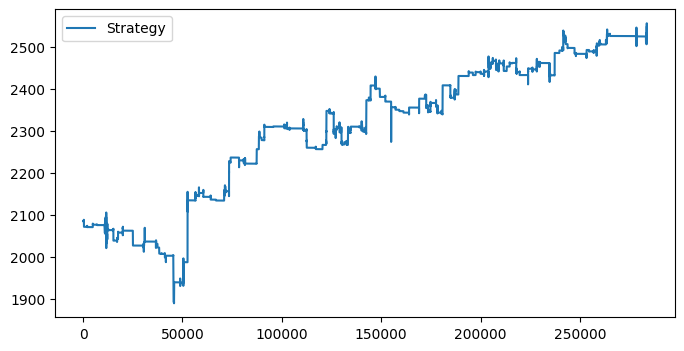

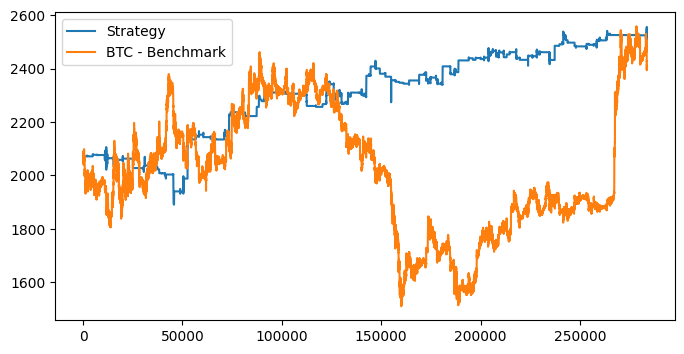

In [20]:
fee = 0.0001

df_bt = df_test.copy()


#Simple backtest routine

def BT(df_bt, fee):
    prev = df_bt.copy()
    
    ## Broker fee calculation
    broker_fee = (abs(prev['signals'])*df_bt['Avg']).sum()*(fee)
    prev['resu'] = -prev["signals"]*prev['Avg']
    df_bt.reset_index(drop=True, inplace=True)
    n = len(df_bt)-1
    
    ## Return of benchmarket for the whole period
    bench = (df_bt['Avg'][n]/df_bt['Avg'][0]-1)*100
    print('Benchmark return %', bench)
    
    
    port = (prev['resu'].sum()+df_bt['Avg'][0]-fee)/df_bt['Close'][0]-1
    
    #print('Portfolio', port*100)
    # Calculation of % change and daily return
    df_bt['Change'] = df_bt['Avg'].diff()
    df_bt['Change'][0] = 0
    df_bt['fee'] = fee * abs(df_bt['signals'])*df_bt['Avg']
    df_bt['PNL'] = df_bt['Change']*df_bt['pos'] - df_bt['fee']
    df_bt['PCT'] = df_bt['PNL']/df_bt['Avg']
    
    #Volatility calculation
    vol = df_bt['PCT'].std()
    n = len(df_bt)
    anual = vol*(365*60*24)**0.5
    print('Volatility', vol*100)
    print('Annualized vol', anual*100)
    
    # Daily ups and downs
    periods = len(df_bt)
    up = len(df_bt['PNL'][df_bt['PNL']>0])
    do = len(df_bt['PNL'][df_bt['PNL']<0])
    
    
    # Return calculation on the period and annualized
    retu = (df_bt['Open'][0] + df_bt['PNL'].sum())/df_bt['Avg'][0] - 1
    print('Return of the period %:', retu*100)
    days = periods/(60*24)
    annu =(retu +1)**(365/days)-1
    print('Return annual %:', annu*100)
    
    
    #Sharpe calculation, 
    print('Sharpe:', (annu*100)/(anual*100))
    df_bt['day'] = df_bt['PNL'].rolling(1440).sum()
    
    #Maximun and minimum daily return
    maxi = df_bt['day'].max()
    loc_max = df_bt['day'].idxmax()
    cl_max = df_bt['Avg'][loc_max]
    mini = df_bt['day'].min()
    loc_min = df_bt['day'].idxmin()
    cl_min = df_bt['Avg'][loc_min]
    
    
    #Total number of signals
    tot_sig = abs(df_bt['signals']).sum()
    print('total signals:', tot_sig)
    print('Max 24 hrs return', maxi/cl_max*100)
    print('Max 24 hrs drawdown', mini/cl_min*100)
    
    #AVG, MAX Holding period

    df_bt['Any_pos'] = df_bt['pos'].apply(lambda x: 1 if x==0 else 0)

    df_bt['gap'] = (df_bt.groupby(['Any_pos','Any_pos', df_bt['Any_pos'].cumsum()])
             ['Any_pos'].transform('size')
             .where(df_bt['Any_pos'].eq(0), other=0)
            )

    up_n = np.count_nonzero(df_bt['gap'])
    avg_up = df_bt['gap'].sum()/up_n
    max_up = df_bt['gap'].max()

    i1, d1 = divmod(avg_up/60, 1)
    i2, d2 = divmod(max_up/60, 1)

    print("Average holding period:", i1,' hours ',d1*60,' minutes' )
    print("Max holding period :", i2,' hours ',d2*60,' minutes')
    df_bt['PNL_cum'] = df_bt['PNL']
    df_bt['PNL_cum'][0] = df_bt['Open'][0]
    df_bt['PNL_cum'] = df_bt['PNL_cum'].cumsum()



    
    plt.figure(figsize=(8,4))
    plt.plot(df_bt['PNL_cum'], label = 'Strategy')

    plt.legend()
    

    plt.figure(figsize=(8,4))
    plt.plot(df_bt['PNL_cum'], label = 'Strategy')
    plt.plot(df_bt['Avg'], label = 'BTC - Benchmark')
    plt.legend()

BT(df_bt, fee)
